# **Notebook 02 : Yield Prediction System**

# Yield Prediction System 

## Project Overview

The Yield Prediction System is the second machine learning module of the YieldCraft AI platform. Its primary objective is to estimate the expected agricultural yield for a selected crop based on historical agricultural records, environmental conditions, and cultivation practices. Accurate yield estimation enables farmers to make informed decisions regarding crop planning, resource allocation, and expected production before the harvesting season.

Unlike the Crop Recommendation System, which identifies the most suitable crop for cultivation, this module focuses on estimating the productivity of the selected crop under the given farming conditions. The prediction is performed using supervised machine learning regression algorithms trained on historical crop production data collected across different states, seasons, and years.

The dataset contains information related to crop type, cultivation year, cropping season, geographical location, cultivated area, annual rainfall, fertilizer usage, pesticide usage, and crop yield. During model development, the **Production** attribute will be excluded from the training process because it directly contributes to the calculation of the target variable (Yield), which would introduce target leakage and lead to unrealistic model performance.

Multiple regression algorithms will be trained and benchmarked using standard evaluation metrics including Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Coefficient of Determination (R² Score), and Cross-Validation Score. The best-performing model will be optimized through hyperparameter tuning and prepared for deployment.

The final trained model, preprocessing objects, evaluation reports, and visualization outputs will be exported as deployment-ready artifacts for integration into the YieldCraft AI backend. The predicted yield generated by this module will be used directly by the Profit Recommendation System to estimate potential revenue and support intelligent agricultural decision-making.

## Objective

The objective of this notebook is to develop a production-ready machine learning regression model capable of accurately predicting agricultural crop yield using historical cultivation records and environmental parameters. The developed model will serve as the Yield Prediction Engine of the YieldCraft AI platform and provide reliable yield estimates that support downstream modules such as Profit Recommendation, Fertilizer Recommendation, Irrigation Planning, and Agricultural Decision Support.

## Expected Output

Given the crop details, cultivation area, weather conditions, fertilizer usage, pesticide usage, season, and geographical location, the model predicts the expected agricultural yield in tonnes per hectare.

Example Prediction

Crop               : Rice, 
State              : Karnataka, 
Season             : Kharif, 
Area               : 2.5 hectares, 
Annual Rainfall    : 1320 mm, 
Fertilizer         : 180 kg, 
Pesticide          : 15 kg, 
****************************************
Predicted Yield    : 5.82 tonnes/hectare, 
Yield Category     : High

# Section 1 : Importing libraries

In [1]:
import warnings

warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    KFold
)

from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor
)

from xgboost import XGBRegressor

from lightgbm import LGBMRegressor

from catboost import CatBoostRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import shap

import joblib

import os
import shutil
import time


# Section 2 : Set Random Seed

In [2]:
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

print(f"Random Seed : {RANDOM_STATE}")

Random Seed : 42


# Section 3 : Load Dataset

In [3]:
DATASET_PATH = "/kaggle/input/datasets/akshatgupta7/crop-yield-in-indian-states-dataset/crop_yield.csv"

df = pd.read_csv(DATASET_PATH)

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [4]:
display(df.head())

display(df.tail())

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
19684,Small millets,1998,Kharif,Nagaland,4000.0,2000,1498.0,395200.00,1160.00,0.500000
19685,Wheat,1998,Rabi,Nagaland,1000.0,3000,1498.0,98800.00,290.00,3.000000
19686,Maize,1997,Kharif,Jammu and Kashmir,310883.0,440900,1356.2,29586735.11,96373.73,1.285000
19687,Rice,1997,Kharif,Jammu and Kashmir,275746.0,5488,1356.2,26242746.82,85481.26,0.016667
19688,Wheat,1997,Rabi,Jammu and Kashmir,239344.0,392160,1356.2,22778368.48,74196.64,1.261818


In [5]:
print("Dataset Columns\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")

Dataset Columns

01. Crop
02. Crop_Year
03. Season
04. State
05. Area
06. Production
07. Annual_Rainfall
08. Fertilizer
09. Pesticide
10. Yield


In [6]:
print("Dataset Columns\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")

Dataset Columns

01. Crop
02. Crop_Year
03. Season
04. State
05. Area
06. Production
07. Annual_Rainfall
08. Fertilizer
09. Pesticide
10. Yield


In [7]:
dtype_df = pd.DataFrame({

    "Column": df.columns,

    "Data Type": df.dtypes.values

})

display(dtype_df)

,Column,Data Type
0,Crop,object
1,Crop_Year,int64
2,Season,object
3,State,object
4,Area,float64
5,Production,int64
6,Annual_Rainfall,float64
7,Fertilizer,float64
8,Pesticide,float64
9,Yield,float64


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 non-null  object 
 1   Crop_Year        19689 non-null  int64  
 2   Season           19689 non-null  object 
 3   State            19689 non-null  object 
 4   Area             19689 non-null  float64
 5   Production       19689 non-null  int64  
 6   Annual_Rainfall  19689 non-null  float64
 7   Fertilizer       19689 non-null  float64
 8   Pesticide        19689 non-null  float64
 9   Yield            19689 non-null  float64
dtypes: float64(5), int64(2), object(3)
memory usage: 1.5+ MB


In [9]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Crop_Year,19689.0,2.009128e+03,6.498099e+00,1997.00,2004.00,2010.00,2.015000e+03,2.020000e+03
Area,19689.0,1.799266e+05,7.328287e+05,0.50,1390.00,9317.00,7.511200e+04,5.080810e+07
Production,19689.0,1.643594e+07,2.630568e+08,0.00,1393.00,13804.00,1.227180e+05,6.326000e+09
Annual_Rainfall,19689.0,1.437755e+03,8.169096e+02,301.30,940.70,1247.60,1.643700e+03,6.552700e+03
Fertilizer,19689.0,2.410331e+07,9.494600e+07,54.17,188014.62,1234957.44,1.000385e+07,4.835407e+09
Pesticide,19689.0,4.884835e+04,2.132874e+05,0.09,356.70,2421.90,2.004170e+04,1.575051e+07
Yield,19689.0,7.995401e+01,8.783062e+02,0.00,0.60,1.03,2.388889e+00,2.110500e+04


In [10]:
missing = pd.DataFrame({

    "Missing Values": df.isnull().sum(),

    "Percentage": (
        df.isnull().sum()/len(df)
    )*100

})

display(missing)

,Missing Values,Percentage
Crop,0,0.0
Crop_Year,0,0.0
Season,0,0.0
State,0,0.0
Area,0,0.0
Production,0,0.0
Annual_Rainfall,0,0.0
Fertilizer,0,0.0
Pesticide,0,0.0
Yield,0,0.0


In [11]:
duplicates = df.duplicated().sum()

print(f"Duplicate Records : {duplicates}")

Duplicate Records : 0


In [12]:
required_columns = [

    "Crop",
    "Crop_Year",
    "Season",
    "State",
    "Area",
    "Production",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide",
    "Yield"

]

missing_columns = list(
    set(required_columns) - set(df.columns)
)

if len(missing_columns) == 0:

    print("Dataset Validation Passed")

else:

    print("Missing Columns")

    print(missing_columns)

Dataset Validation Passed


# Section 4 : Dataset Understanding

In [13]:
overview = pd.DataFrame({

    "Column": df.columns,
    "Data Type": df.dtypes.values,
    "Non-Null Count": df.count().values,
    "Null Count": df.isnull().sum().values,
    "Unique Values": df.nunique().values

})

display(overview)

,Column,Data Type,Non-Null Count,Null Count,Unique Values
0,Crop,object,19689,0,55
1,Crop_Year,int64,19689,0,24
2,Season,object,19689,0,6
3,State,object,19689,0,30
4,Area,float64,19689,0,13644
5,Production,int64,19689,0,14016
6,Annual_Rainfall,float64,19689,0,634
7,Fertilizer,float64,19689,0,18598
8,Pesticide,float64,19689,0,17405
9,Yield,float64,19689,0,13551


In [14]:
numerical_features = df.select_dtypes(include=np.number).columns.tolist()

categorical_features = df.select_dtypes(include="object").columns.tolist()

print("="*60)
print("NUMERICAL FEATURES")
print("="*60)

print(numerical_features)

print("\n")

print("="*60)
print("CATEGORICAL FEATURES")
print("="*60)

print(categorical_features)

NUMERICAL FEATURES
['Crop_Year', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']


CATEGORICAL FEATURES
['Crop', 'Season', 'State']


In [15]:
unique_df = pd.DataFrame({

    "Column": df.columns,
    "Unique Values": [df[col].nunique() for col in df.columns]

})

display(unique_df)

,Column,Unique Values
0,Crop,55
1,Crop_Year,24
2,Season,6
3,State,30
4,Area,13644
5,Production,14016
6,Annual_Rainfall,634
7,Fertilizer,18598
8,Pesticide,17405
9,Yield,13551


In [16]:
display(df["Yield"].describe())

count    19689.000000
mean        79.954009
std        878.306193
min          0.000000
25%          0.600000
50%          1.030000
75%          2.388889
max      21105.000000
Name: Yield, dtype: float64

In [17]:
crop_counts = (
    df["Crop"]
    .value_counts()
    .reset_index()
)

crop_counts.columns = ["Crop", "Count"]

display(crop_counts)

,Crop,Count
0,Rice,1197
1,Maize,975
2,Moong(Green Gram),740
3,Urad,733
4,Groundnut,725
5,Sesamum,685
6,Potato,628
7,Sugarcane,605
8,Wheat,545
9,Rapeseed &Mustard,528


In [18]:
state_counts = (
    df["State"]
    .value_counts()
    .reset_index()
)

state_counts.columns = ["State", "Count"]

display(state_counts)

,State,Count
0,Karnataka,1432
1,Andhra Pradesh,1266
2,West Bengal,1094
3,Chhattisgarh,915
4,Bihar,896
5,Madhya Pradesh,845
6,Uttar Pradesh,825
7,Tamil Nadu,822
8,Gujarat,817
9,Maharashtra,770


In [19]:
season_counts = (
    df["Season"]
    .value_counts()
    .reset_index()
)

season_counts.columns = ["Season", "Count"]

display(season_counts)

,Season,Count
0,Kharif,8232
1,Rabi,5742
2,Whole Year,3717
3,Summer,1195
4,Autumn,414
5,Winter,389


In [20]:
print(f"Minimum Year : {df['Crop_Year'].min()}")

print(f"Maximum Year : {df['Crop_Year'].max()}")

print(f"Total Years  : {df['Crop_Year'].nunique()}")

Minimum Year : 1997
Maximum Year : 2020
Total Years  : 24


In [21]:
print("Features Used For Training")

training_columns = [

    "Crop",
    "Crop_Year",
    "Season",
    "State",
    "Area",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"

]

for col in training_columns:
    print("✓", col)

print("\nExcluded Feature")

print("✗ Production")

Features Used For Training
✓ Crop
✓ Crop_Year
✓ Season
✓ State
✓ Area
✓ Annual_Rainfall
✓ Fertilizer
✓ Pesticide

Excluded Feature
✗ Production


## Create Training dataset

In [22]:
train_df = df.drop(columns=["Production"])

display(train_df.head())

,Crop,Crop_Year,Season,State,Area,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,2051.4,165500.63,539.09,0.420909


In [23]:
print("="*60)
print("FINAL FEATURES")
print("="*60)

for column in train_df.columns:
    print(column)

FINAL FEATURES
Crop
Crop_Year
Season
State
Area
Annual_Rainfall
Fertilizer
Pesticide
Yield


# Section 5 : Exploratory Data Analysis (EDA)

## Exploratory Data Analysis Summary

Key observations from the exploratory data analysis include:

- The dataset contains a combination of categorical and numerical agricultural features.
- Yield distribution indicates the presence of extreme values that require further analysis.
- Crop productivity varies considerably across different crop types.
- Significant regional variation is observed across states.
- Seasonal effects influence agricultural yield.
- Rainfall, fertilizer, and pesticide usage exhibit varying relationships with crop yield.
- Numerical features show different scales and distributions, motivating appropriate preprocessing before model training.
- The exclusion of the Production feature prevents target leakage and ensures a realistic prediction pipeline.

In [24]:
print("="*60)
print("DATASET DIMENSIONS")
print("="*60)

print(f"Rows    : {train_df.shape[0]:,}")
print(f"Columns : {train_df.shape[1]}")

DATASET DIMENSIONS
Rows    : 19,689
Columns : 9


In [25]:
print("NUMERICAL FEATURES")
print("="*60)

display(pd.DataFrame(numerical_features, columns=["Numerical Features"]))

print("="*60)
print("CATEGORICAL FEATURES")
print("="*60)

display(pd.DataFrame(categorical_features, columns=["Categorical Features"]))

NUMERICAL FEATURES


,Numerical Features
0,Crop_Year
1,Area
2,Production
3,Annual_Rainfall
4,Fertilizer
5,Pesticide
6,Yield


CATEGORICAL FEATURES


,Categorical Features
0,Crop
1,Season
2,State


In [26]:
display(train_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Crop_Year,19689.0,2.009128e+03,6.498099e+00,1997.00,2004.00,2010.00,2.015000e+03,2.020000e+03
Area,19689.0,1.799266e+05,7.328287e+05,0.50,1390.00,9317.00,7.511200e+04,5.080810e+07
Annual_Rainfall,19689.0,1.437755e+03,8.169096e+02,301.30,940.70,1247.60,1.643700e+03,6.552700e+03
Fertilizer,19689.0,2.410331e+07,9.494600e+07,54.17,188014.62,1234957.44,1.000385e+07,4.835407e+09
Pesticide,19689.0,4.884835e+04,2.132874e+05,0.09,356.70,2421.90,2.004170e+04,1.575051e+07
Yield,19689.0,7.995401e+01,8.783062e+02,0.00,0.60,1.03,2.388889e+00,2.110500e+04


In [27]:
missing = pd.DataFrame({

    "Missing": train_df.isnull().sum(),

    "Percentage": train_df.isnull().mean()*100

})

display(missing)

,Missing,Percentage
Crop,0,0.0
Crop_Year,0,0.0
Season,0,0.0
State,0,0.0
Area,0,0.0
Annual_Rainfall,0,0.0
Fertilizer,0,0.0
Pesticide,0,0.0
Yield,0,0.0


In [28]:
duplicates = train_df.duplicated().sum()

print(f"Duplicate Records : {duplicates}")

Duplicate Records : 0


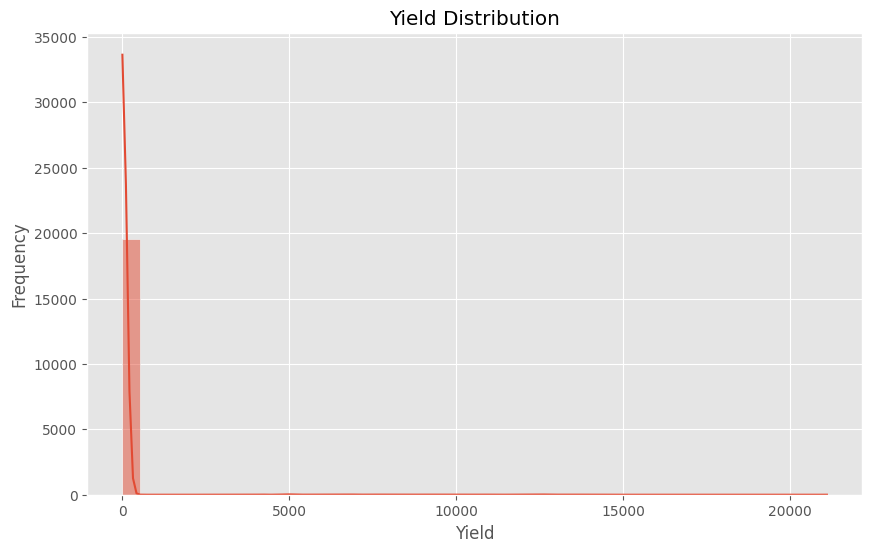

In [29]:
plt.figure(figsize=(10,6))

sns.histplot(
    train_df["Yield"],
    bins=40,
    kde=True
)

plt.title("Yield Distribution")
plt.xlabel("Yield")
plt.ylabel("Frequency")

plt.show()

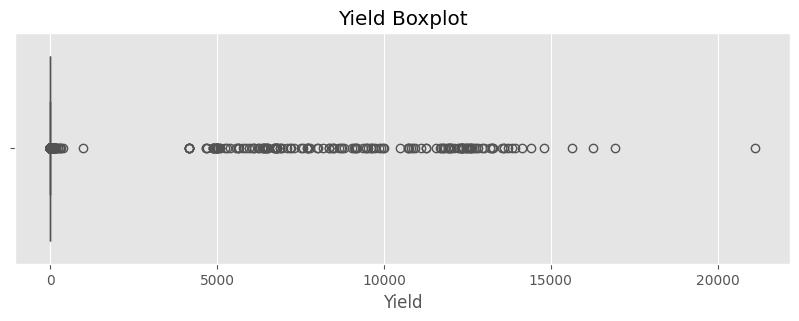

In [30]:
plt.figure(figsize=(10,3))

sns.boxplot(
    x=train_df["Yield"]
)

plt.title("Yield Boxplot")

plt.show()

In [31]:
display(train_df["Yield"].describe())

count    19689.000000
mean        79.954009
std        878.306193
min          0.000000
25%          0.600000
50%          1.030000
75%          2.388889
max      21105.000000
Name: Yield, dtype: float64

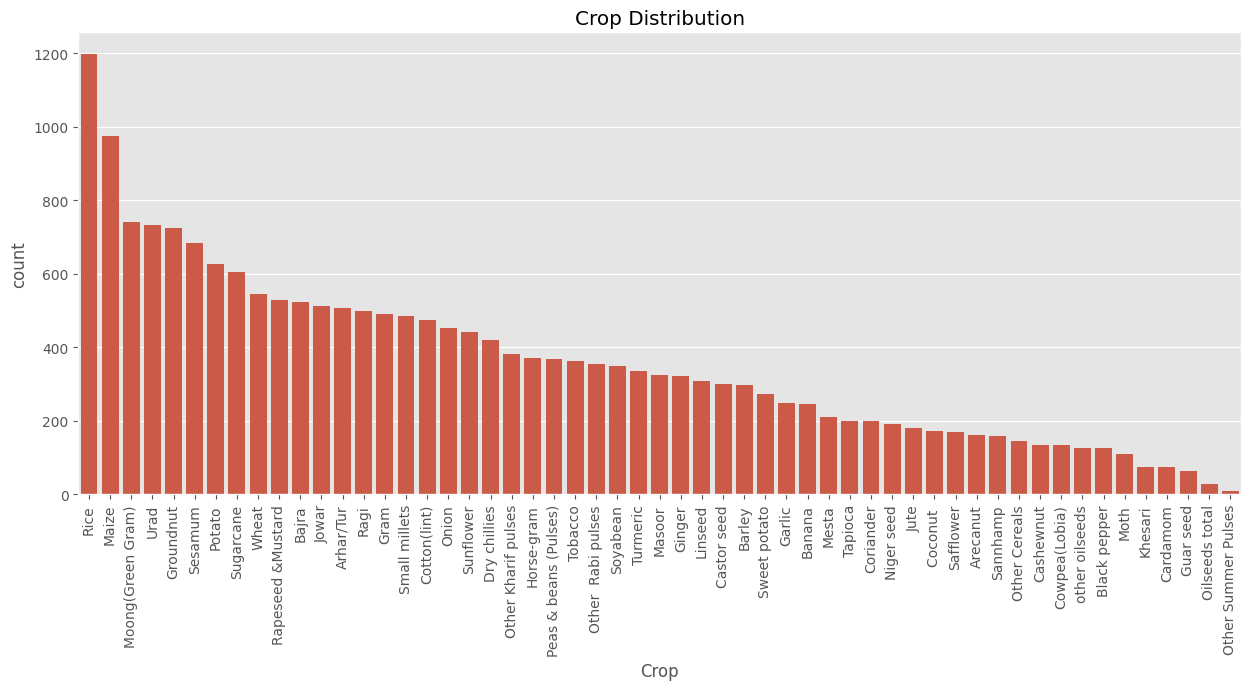

In [32]:
plt.figure(figsize=(15,6))

sns.countplot(

    data=train_df,

    x="Crop",

    order=train_df["Crop"].value_counts().index

)

plt.xticks(rotation=90)

plt.title("Crop Distribution")

plt.show()

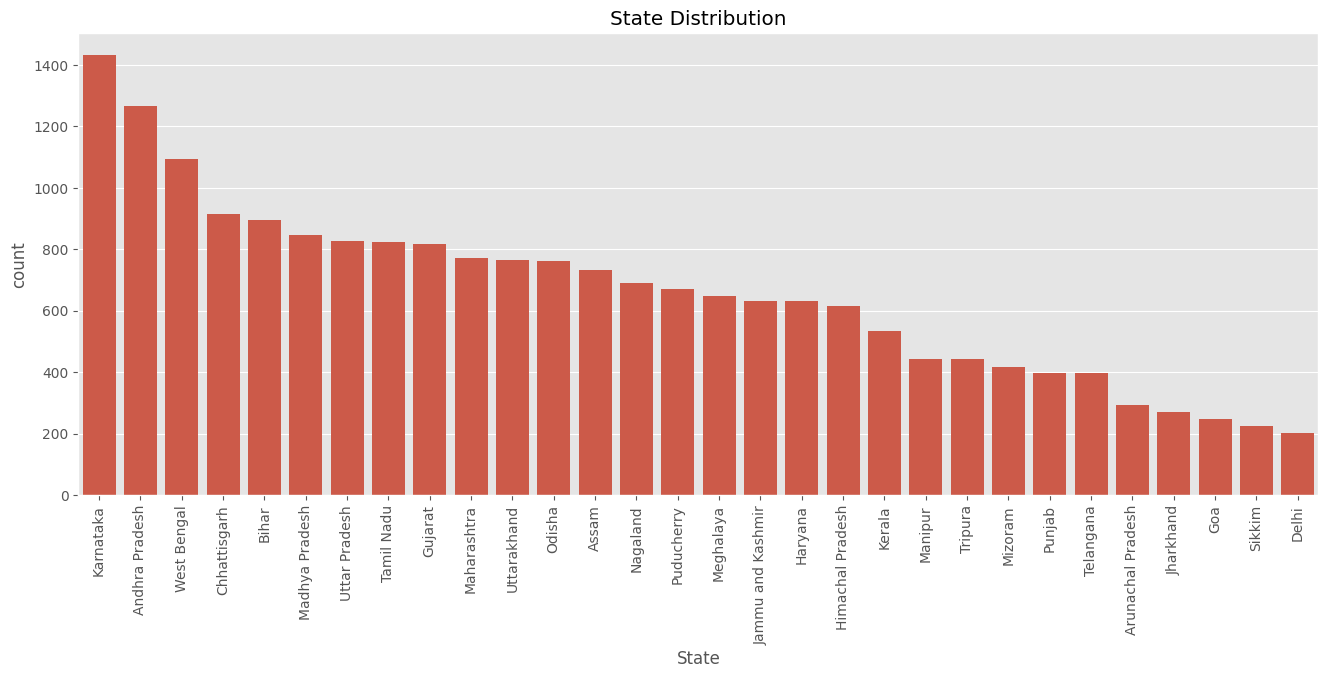

In [33]:
plt.figure(figsize=(16,6))

sns.countplot(

    data=train_df,

    x="State",

    order=train_df["State"].value_counts().index

)

plt.xticks(rotation=90)

plt.title("State Distribution")

plt.show()

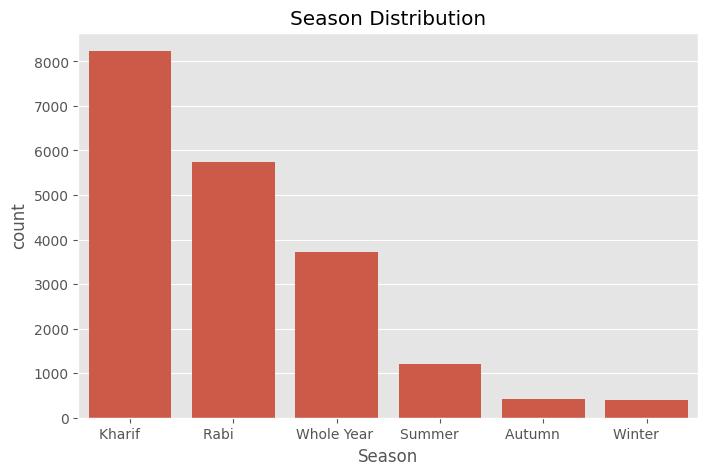

In [34]:
plt.figure(figsize=(8,5))

sns.countplot(

    data=train_df,

    x="Season",

    order=train_df["Season"].value_counts().index

)

plt.title("Season Distribution")

plt.show()

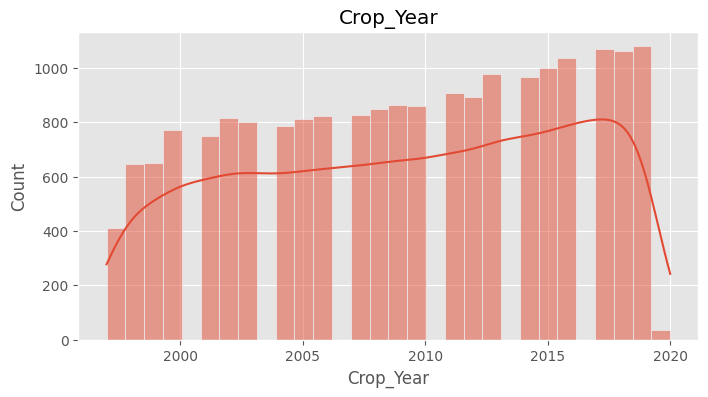

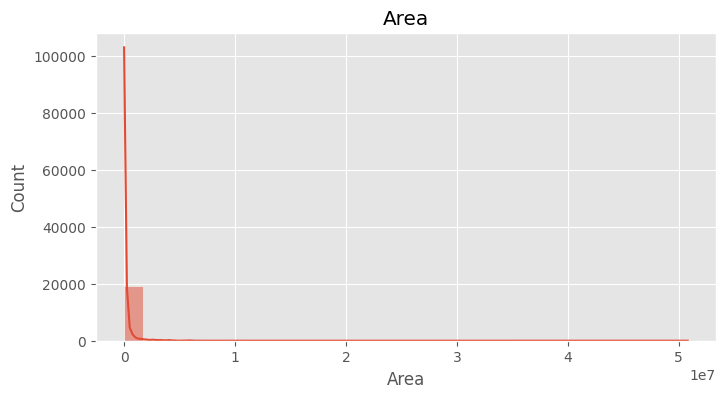

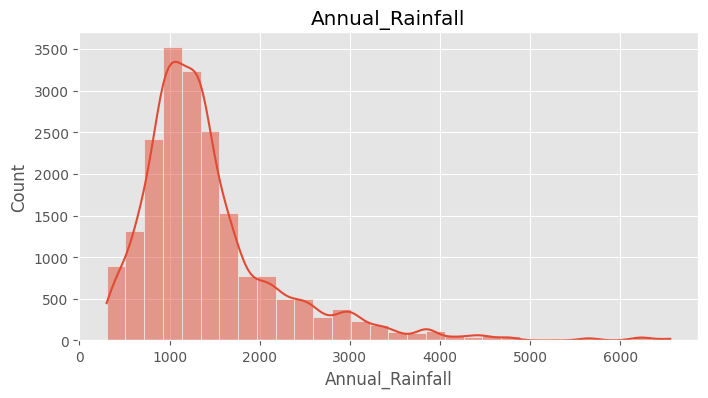

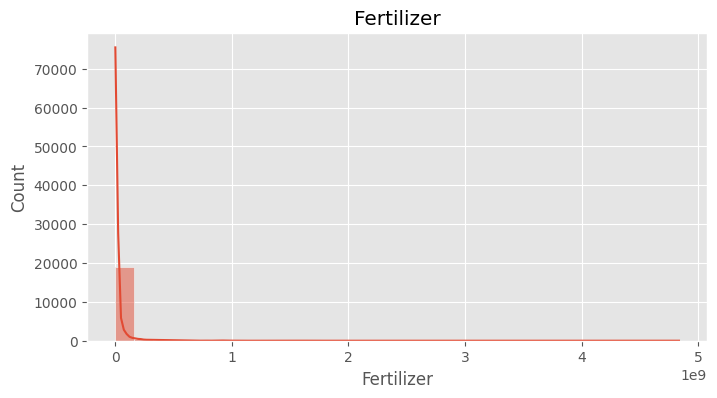

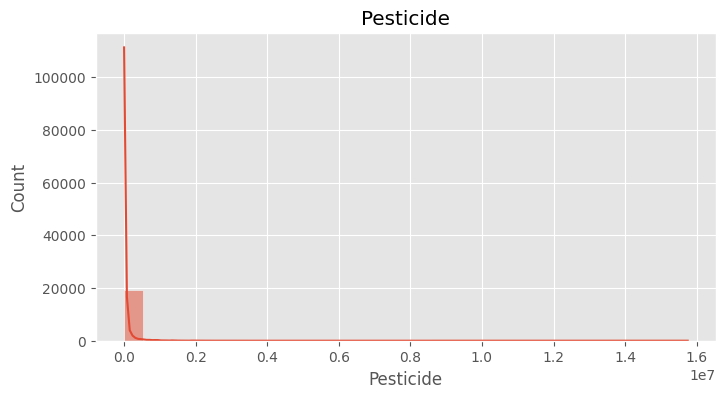

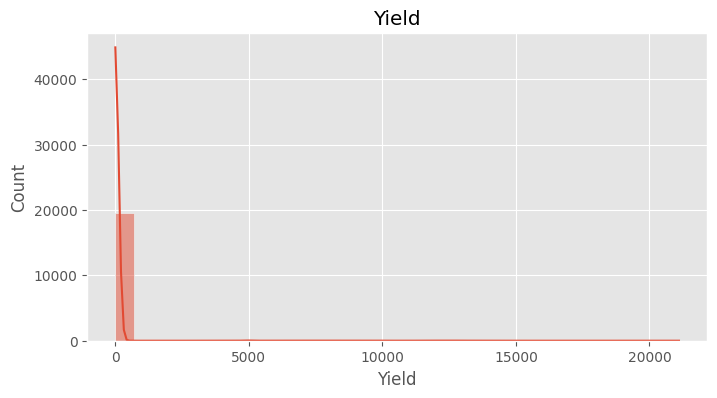

In [35]:
numeric_columns = [

    "Crop_Year",
    "Area",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide",
    "Yield"

]

for column in numeric_columns:

    plt.figure(figsize=(8,4))

    sns.histplot(

        train_df[column],

        kde=True,

        bins=30

    )

    plt.title(column)

    plt.show()

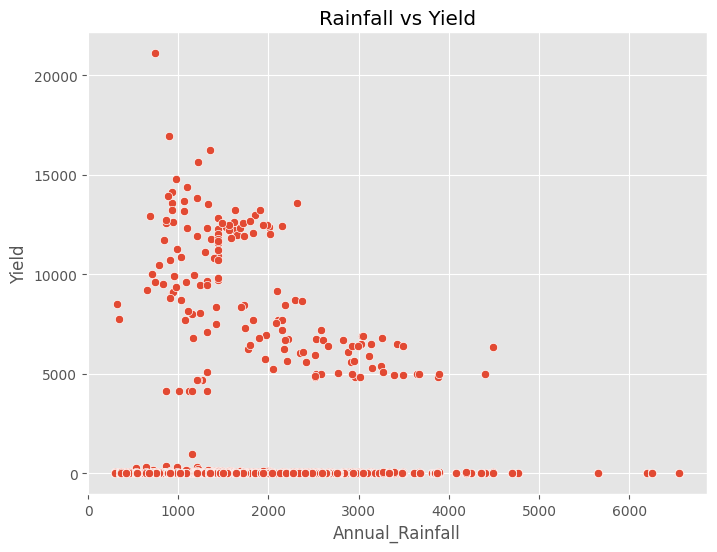

In [36]:
plt.figure(figsize=(8,6))

sns.scatterplot(

    data=train_df,

    x="Annual_Rainfall",

    y="Yield"

)

plt.title("Rainfall vs Yield")

plt.show()

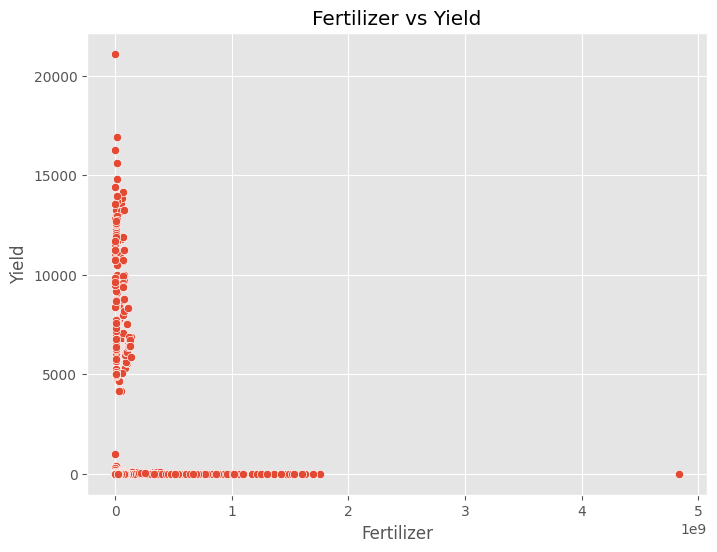

In [37]:
plt.figure(figsize=(8,6))

sns.scatterplot(

    data=train_df,

    x="Fertilizer",

    y="Yield"

)

plt.title("Fertilizer vs Yield")

plt.show()

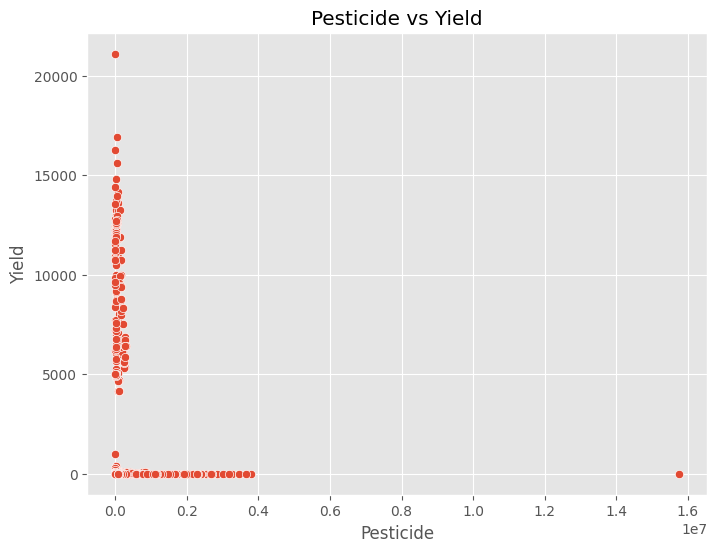

In [38]:
plt.figure(figsize=(8,6))

sns.scatterplot(

    data=train_df,

    x="Pesticide",

    y="Yield"

)

plt.title("Pesticide vs Yield")

plt.show()

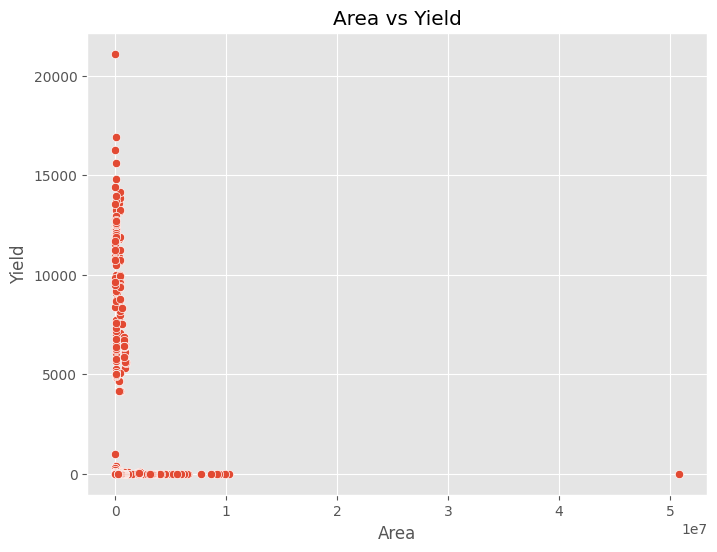

In [39]:
plt.figure(figsize=(8,6))

sns.scatterplot(

    data=train_df,

    x="Area",

    y="Yield"

)

plt.title("Area vs Yield")

plt.show()

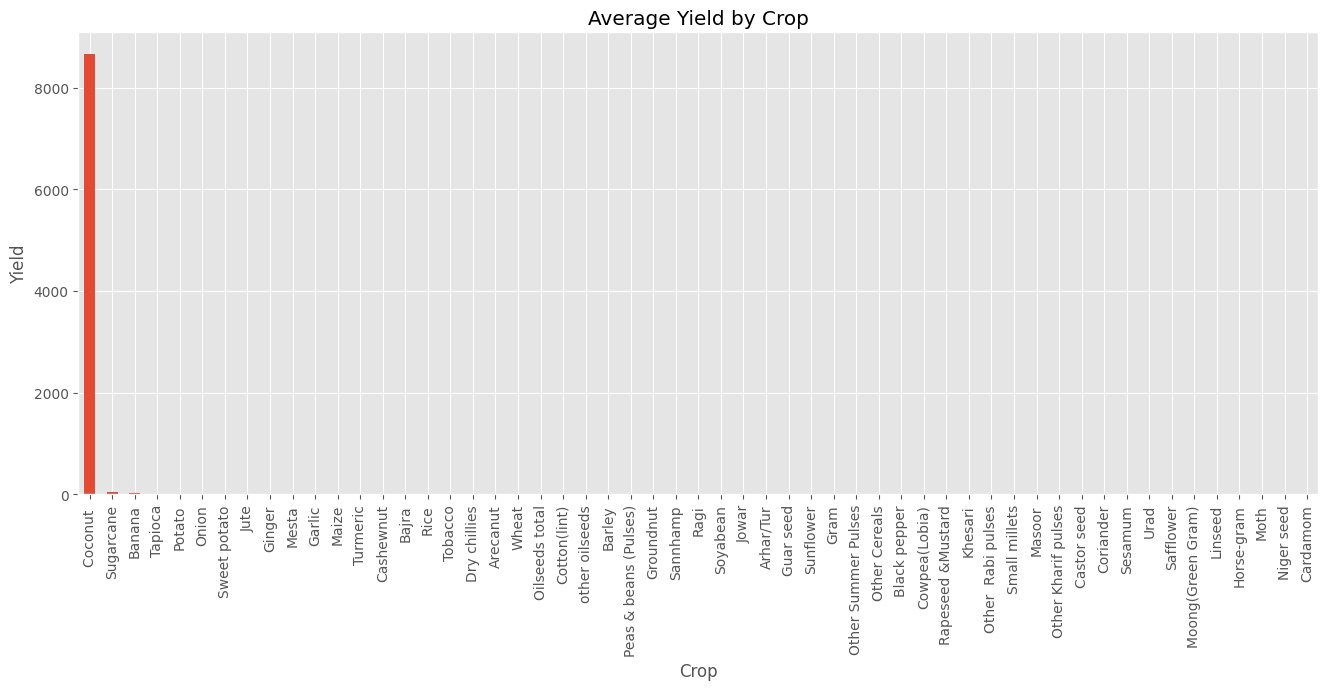

In [40]:
crop_yield = (

    train_df
    .groupby("Crop")["Yield"]
    .mean()
    .sort_values(ascending=False)

)

plt.figure(figsize=(16,6))

crop_yield.plot(kind="bar")

plt.title("Average Yield by Crop")

plt.ylabel("Yield")

plt.show()

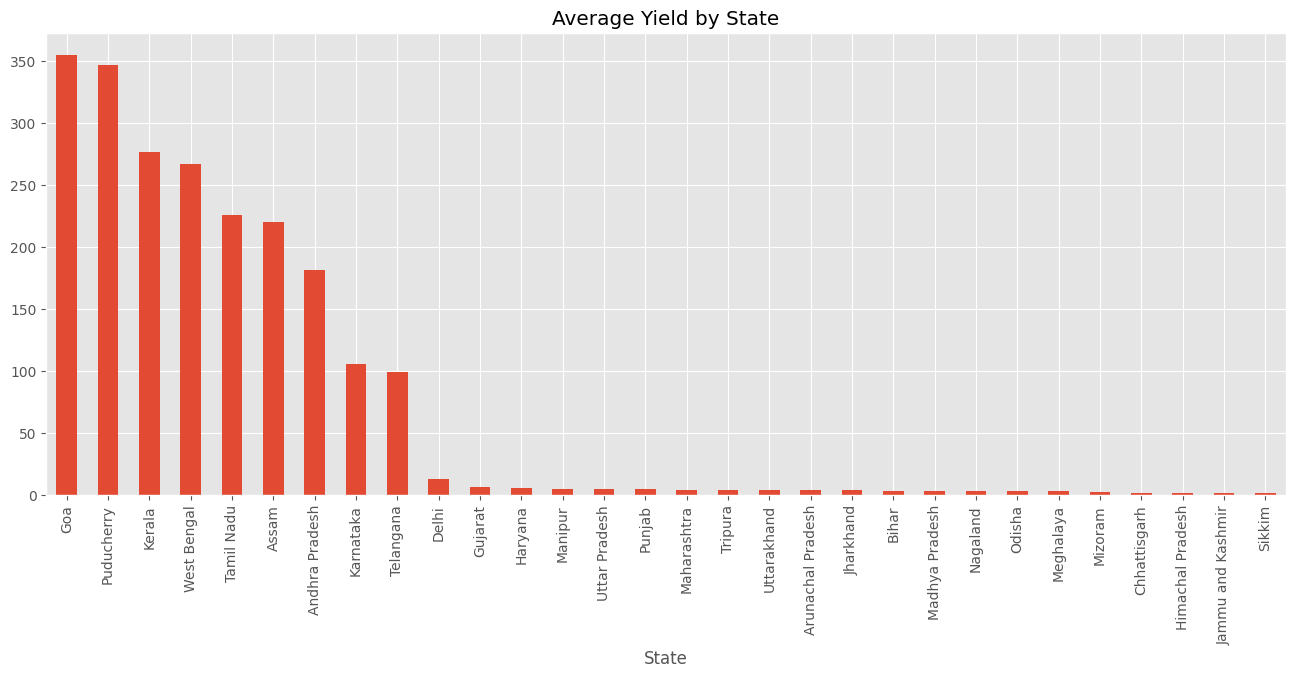

In [41]:
state_yield = (

    train_df
    .groupby("State")["Yield"]
    .mean()
    .sort_values(ascending=False)

)

plt.figure(figsize=(16,6))

state_yield.plot(kind="bar")

plt.title("Average Yield by State")

plt.show()

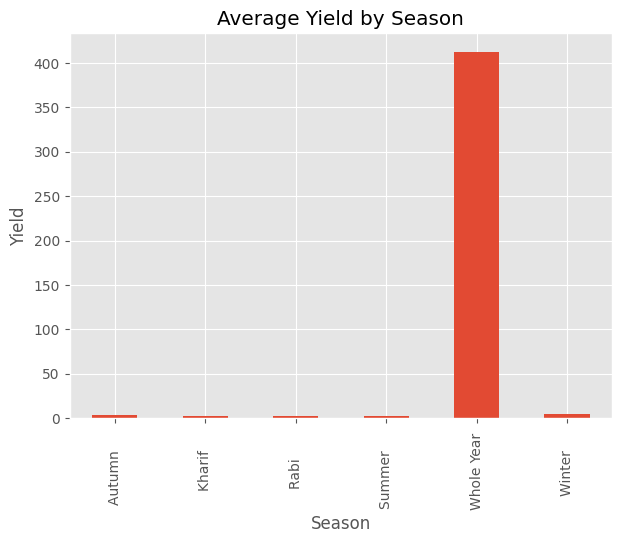

In [42]:
season_yield = (

    train_df
    .groupby("Season")["Yield"]
    .mean()

)

plt.figure(figsize=(7,5))

season_yield.plot(kind="bar")

plt.ylabel("Yield")

plt.title("Average Yield by Season")

plt.show()

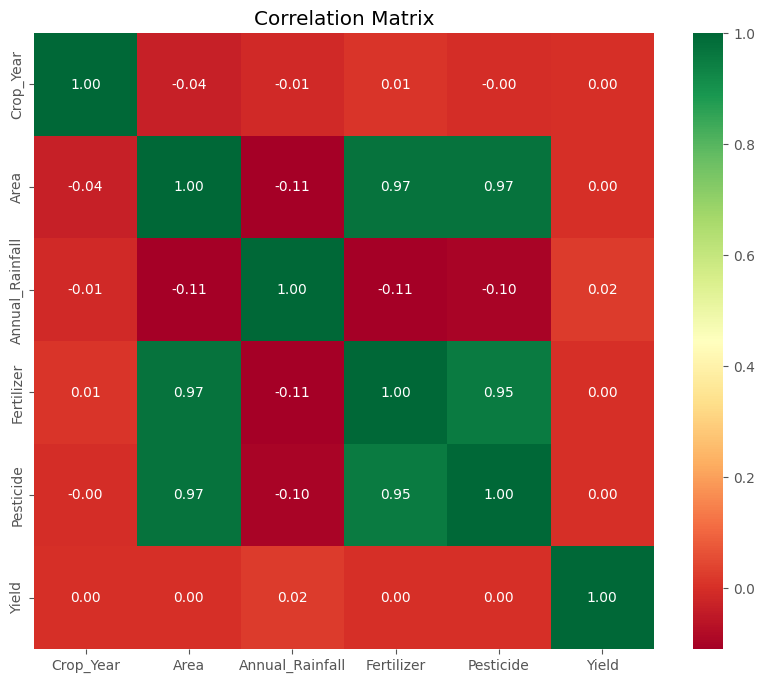

In [43]:
plt.figure(figsize=(10,8))

sns.heatmap(

    train_df.select_dtypes(include=np.number).corr(),

    annot=True,

    cmap="RdYlGn",

    fmt=".2f"

)

plt.title("Correlation Matrix")

plt.show()

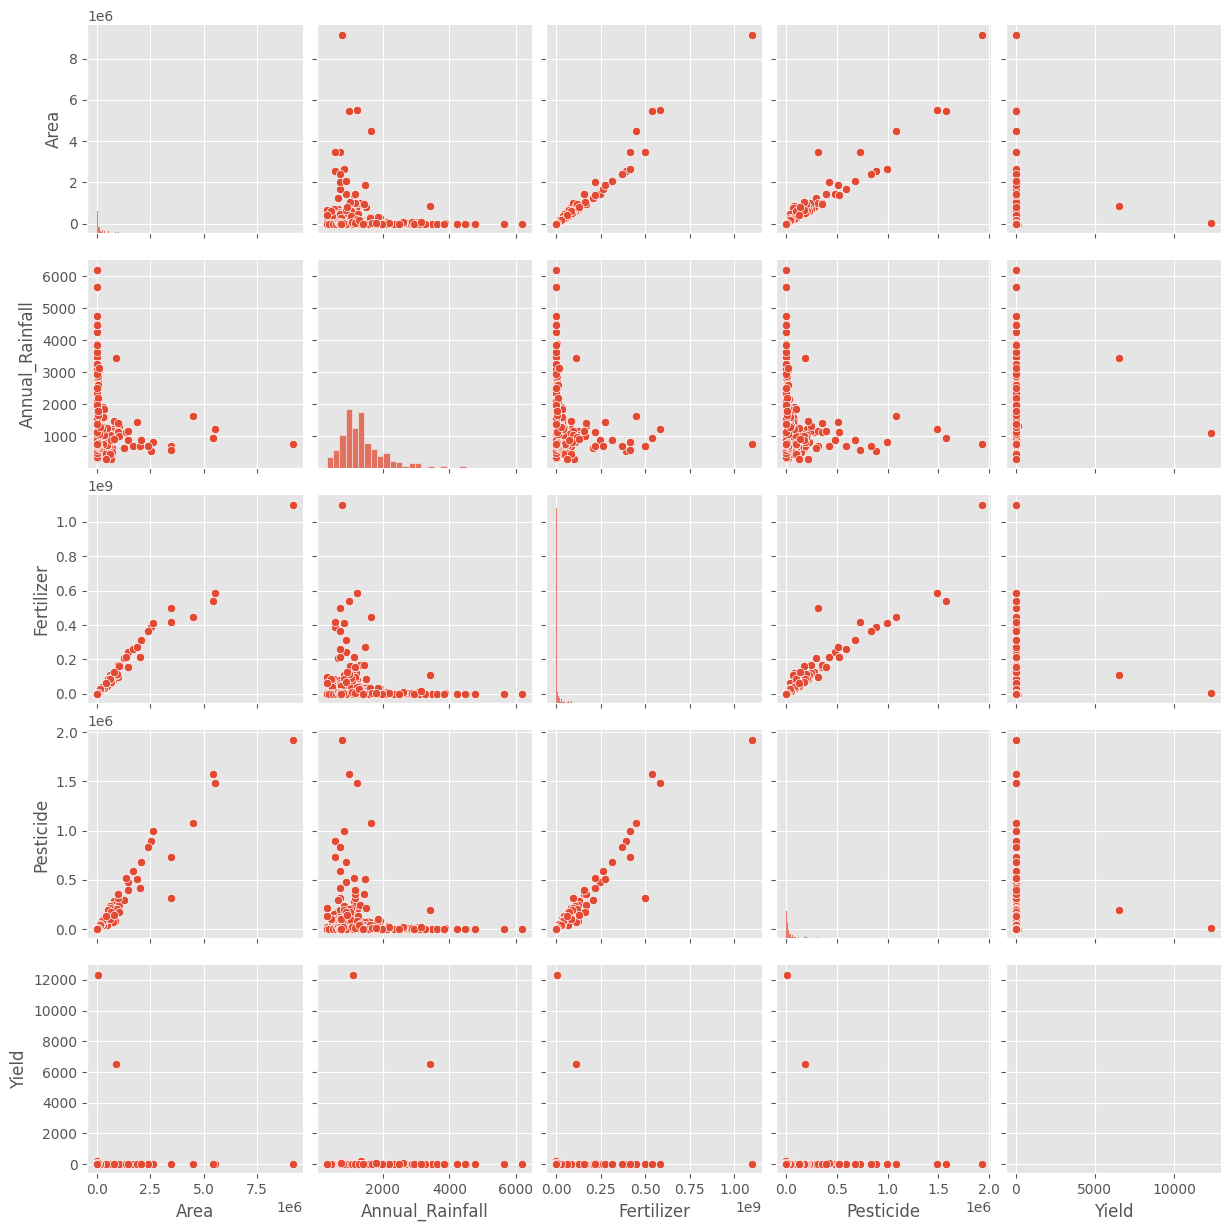

In [44]:
sample = train_df.sample(

    min(500, len(train_df)),

    random_state=42

)

sns.pairplot(

    sample[
        [
            "Area",
            "Annual_Rainfall",
            "Fertilizer",
            "Pesticide",
            "Yield"
        ]
    ]
)

plt.show()

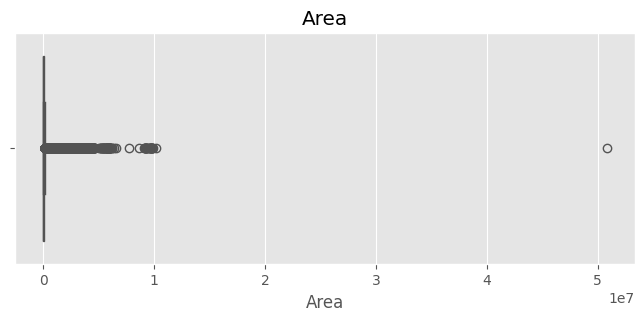

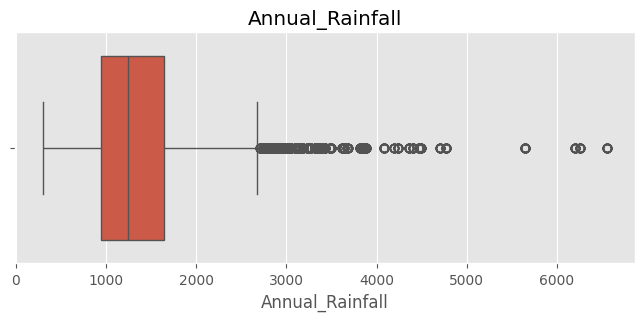

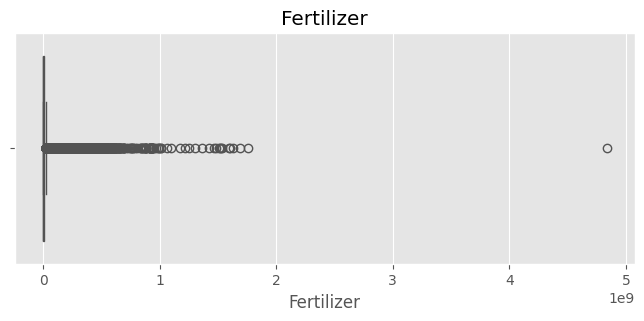

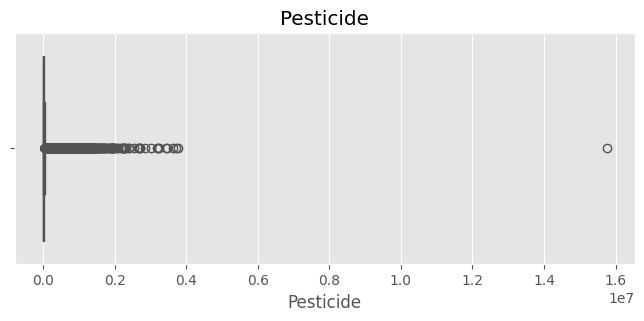

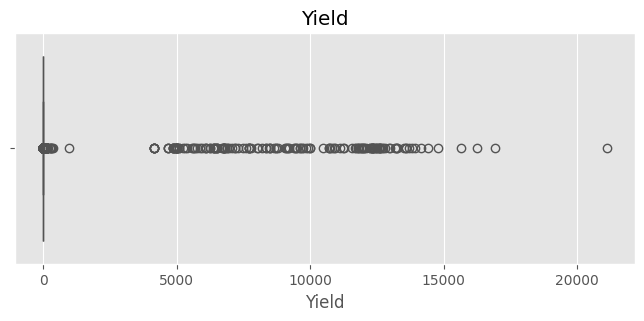

In [45]:
features = [

    "Area",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide",
    "Yield"

]

for feature in features:

    plt.figure(figsize=(8,3))

    sns.boxplot(

        x=train_df[feature]

    )

    plt.title(feature)

    plt.show()

# Section 6 : Data Preprocessing

In [46]:
FEATURES = [

    "Crop",
    "Crop_Year",
    "Season",
    "State",
    "Area",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"

]

TARGET = "Yield"

In [47]:
X = train_df[FEATURES].copy()

y = train_df[TARGET].copy()

print("Feature Shape :", X.shape)

print("Target Shape  :", y.shape)

Feature Shape : (19689, 8)
Target Shape  : (19689,)


In [48]:
assert "Production" not in X.columns

print("✓ Production column removed")

print("✓ No Target Leakage Found")

✓ Production column removed
✓ No Target Leakage Found


In [49]:
categorical_features = [

    "Crop",
    "Season",
    "State"

]

numerical_features = [

    "Crop_Year",
    "Area",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"

]

print("Categorical Features")

print(categorical_features)

print()

print("Numerical Features")

print(numerical_features)

Categorical Features
['Crop', 'Season', 'State']

Numerical Features
['Crop_Year', 'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']


In [50]:
preprocessor = ColumnTransformer(

    transformers=[

        (

            "categorical",

            OneHotEncoder(

                handle_unknown="ignore"

            ),

            categorical_features

        ),

        (

            "numerical",

            StandardScaler(),

            numerical_features

        )

    ]

)

print(preprocessor)

ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Crop', 'Season', 'State']),
                                ('numerical', StandardScaler(),
                                 ['Crop_Year', 'Area', 'Annual_Rainfall',
                                  'Fertilizer', 'Pesticide'])])


In [51]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42

)

print("Training Samples :", len(X_train))

print("Testing Samples  :", len(X_test))

Training Samples : 15751
Testing Samples  : 3938


In [52]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training Shape :", X_train_processed.shape)

print("Testing Shape  :", X_test_processed.shape)

Training Shape : (15751, 96)
Testing Shape  : (3938, 96)


In [53]:
feature_names = preprocessor.get_feature_names_out()

print("Total Processed Features")

print(len(feature_names))

display(pd.DataFrame(feature_names, columns=["Features"]))

Total Processed Features
96


,Features
0,categorical__Crop_Arecanut
1,categorical__Crop_Arhar/Tur
2,categorical__Crop_Bajra
3,categorical__Crop_Banana
4,categorical__Crop_Barley
...,...
91,numerical__Crop_Year
92,numerical__Area
93,numerical__Annual_Rainfall
94,numerical__Fertilizer


In [54]:
if hasattr(X_train_processed, "toarray"):

    processed_df = pd.DataFrame(

        X_train_processed.toarray(),

        columns=feature_names

    )

else:

    processed_df = pd.DataFrame(

        X_train_processed,

        columns=feature_names

    )

print(processed_df.isnull().sum().sum())

0


In [55]:

display(

    processed_df.describe().T.head(20)

)

,count,mean,std,min,25%,50%,75%,max
categorical__Crop_Arecanut,15751.0,0.007936,0.088733,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Arhar/Tur,15751.0,0.025459,0.157519,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Bajra,15751.0,0.026982,0.162037,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Banana,15751.0,0.011999,0.108885,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Barley,15751.0,0.015555,0.123748,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Black pepper,15751.0,0.006603,0.080991,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Cardamom,15751.0,0.003619,0.060050,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Cashewnut,15751.0,0.006793,0.082143,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Castor seed,15751.0,0.014856,0.120981,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Coconut,15751.0,0.008761,0.093194,0.0,0.0,0.0,0.0,1.0


In [56]:

display(

    processed_df.describe().T.head(20)

)

,count,mean,std,min,25%,50%,75%,max
categorical__Crop_Arecanut,15751.0,0.007936,0.088733,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Arhar/Tur,15751.0,0.025459,0.157519,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Bajra,15751.0,0.026982,0.162037,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Banana,15751.0,0.011999,0.108885,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Barley,15751.0,0.015555,0.123748,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Black pepper,15751.0,0.006603,0.080991,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Cardamom,15751.0,0.003619,0.060050,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Cashewnut,15751.0,0.006793,0.082143,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Castor seed,15751.0,0.014856,0.120981,0.0,0.0,0.0,0.0,1.0
categorical__Crop_Coconut,15751.0,0.008761,0.093194,0.0,0.0,0.0,0.0,1.0


In [57]:
joblib.dump(

    preprocessor,

    "yield_preprocessor.pkl"

)

print("Preprocessor saved.")

Preprocessor saved.


# Section 7 : Model Benchmarking

## Define Regression Models

In [58]:
models = {

    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(random_state=RANDOM_STATE),

    "Lasso Regression": Lasso(random_state=RANDOM_STATE),

    "Decision Tree": DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        random_state=RANDOM_STATE,
        objective="reg:squarederror",
        n_jobs=-1
    ),

    "LightGBM": LGBMRegressor(
        random_state=RANDOM_STATE,
        verbose=-1
    ),

    "CatBoost": CatBoostRegressor(
        random_state=RANDOM_STATE,
        verbose=0
    )

}

print(f"Total Models : {len(models)}")

Total Models : 9


In [59]:
from sklearn.pipeline import Pipeline

results = []

trained_models = {}

def benchmark_model(name, model):

    pipeline = Pipeline([

        ("preprocessor", preprocessor),

        ("model", model)

    ])
    # -------------------------
    # Training
    # -------------------------

    start = time.time()

    pipeline.fit(X_train, y_train)

    train_time = time.time() - start

    # -------------------------
    # Prediction
    # -------------------------

    start = time.time()

    predictions = pipeline.predict(X_test)

    prediction_time = time.time() - start

    # -------------------------
    # Metrics
    # -------------------------

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    cv_score = cross_val_score(

        pipeline,

        X,

        y,

        cv=5,

        scoring="r2",

        n_jobs=-1

    ).mean()

    results.append({

        "Model": name,

        "MAE": mae,

        "MSE": mse,

        "RMSE": rmse,

        "R² Score": r2,

        "CV R²": cv_score,

        "Train Time (s)": train_time,

        "Prediction Time (s)": prediction_time

    })

    trained_models[name] = pipeline

    print(f"Completed : {name}")

In [60]:
for model_name, model in models.items():

    benchmark_model(model_name, model)

Completed : Linear Regression
Completed : Ridge Regression
Completed : Lasso Regression
Completed : Decision Tree
Completed : Random Forest
Completed : Extra Trees
Completed : XGBoost


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Completed : LightGBM
Completed : CatBoost


In [61]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(

    by="R² Score",

    ascending=False

)

results_df.reset_index(drop=True, inplace=True)

display(results_df)

,Model,MAE,MSE,RMSE,R² Score,CV R²,Train Time (s),Prediction Time (s)
0,Random Forest,9.445852,15886.751808,126.042659,0.980172,0.940984,35.809792,0.104752
1,Extra Trees,8.852037,19189.679049,138.526817,0.976050,0.958929,40.747808,0.088520
2,CatBoost,11.552599,19461.044791,139.502849,0.975711,0.934645,3.283567,0.018030
3,Decision Tree,11.798767,32196.648800,179.434246,0.959816,0.884842,1.313509,0.010953
4,XGBoost,15.228585,62641.471930,250.282784,0.921819,0.953899,0.766204,0.020542
5,LightGBM,19.227285,63016.066655,251.030011,0.921352,0.898422,0.217478,0.020236
6,Linear Regression,63.884930,151851.133152,389.680809,0.810480,0.782285,0.070239,0.013587
7,Ridge Regression,64.204478,152004.430877,389.877456,0.810288,0.782410,0.062957,0.013732
8,Lasso Regression,53.373525,153386.693895,391.646134,0.808563,0.783584,0.061795,0.012866


In [62]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("="*60)

print("BEST MODEL")

print("="*60)

print(best_model_name)

BEST MODEL
Random Forest


In [63]:
results_df.to_csv(

    "benchmark_results.csv",

    index=False

)

print("Benchmark results saved.")

Benchmark results saved.


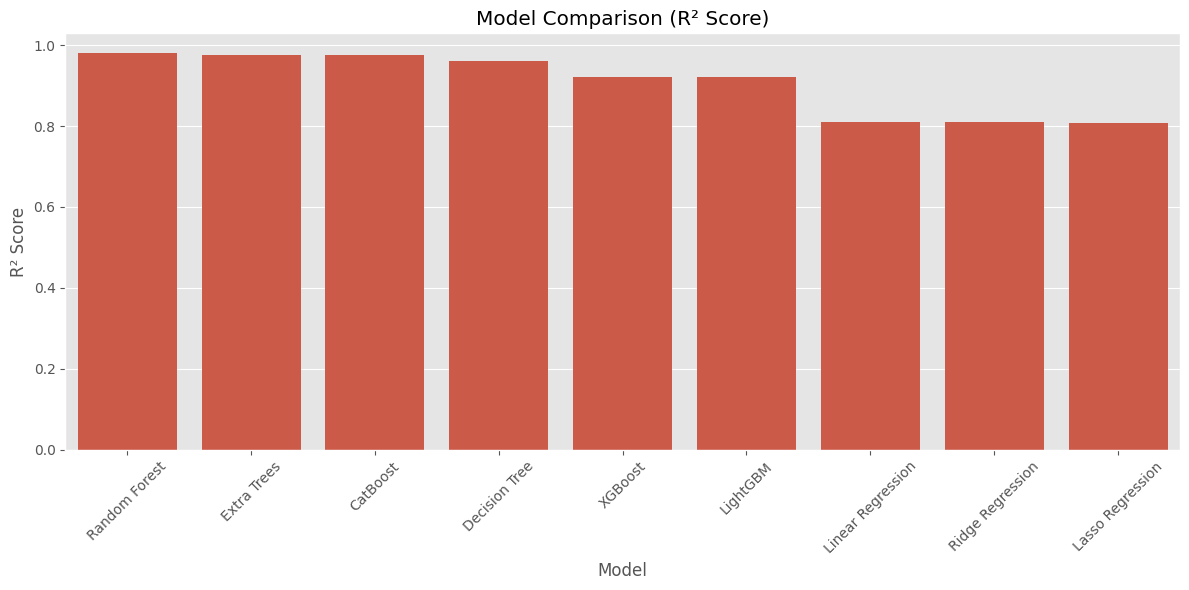

In [64]:
plt.figure(figsize=(12,6))

sns.barplot(

    data=results_df,

    x="Model",

    y="R² Score"

)

plt.xticks(rotation=45)

plt.title("Model Comparison (R² Score)")

plt.tight_layout()

plt.show()

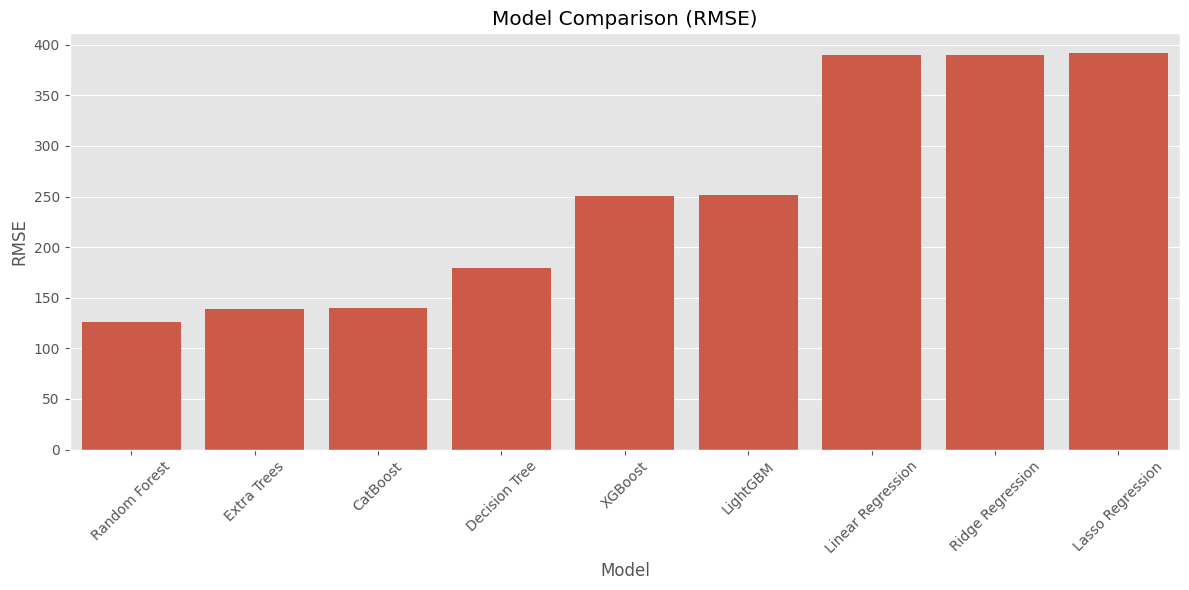

In [65]:
plt.figure(figsize=(12,6))

sns.barplot(

    data=results_df,

    x="Model",

    y="RMSE"

)

plt.xticks(rotation=45)

plt.title("Model Comparison (RMSE)")

plt.tight_layout()

plt.show()

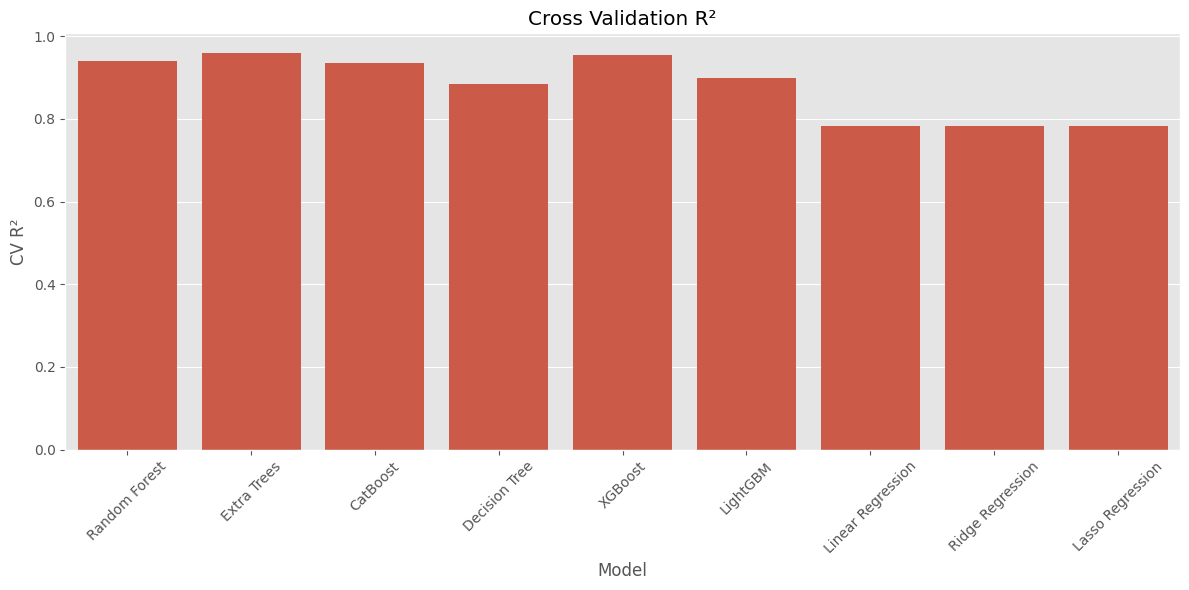

In [66]:
plt.figure(figsize=(12,6))

sns.barplot(

    data=results_df,

    x="Model",

    y="CV R²"

)

plt.xticks(rotation=45)

plt.title("Cross Validation R²")

plt.tight_layout()

plt.show()

# Section 8 : Hyperparameter Tuning (Random Forest)

In [67]:
param_grid = {

    "model__n_estimators": [100, 200, 300],

    "model__max_depth": [10, 20, 30, None],

    "model__min_samples_split": [2, 5, 10],

    "model__min_samples_leaf": [1, 2, 4],

    "model__max_features": ["sqrt", "log2"]

}

print("Total Parameter Combinations:",

      len(param_grid["model__n_estimators"]) *
      len(param_grid["model__max_depth"]) *
      len(param_grid["model__min_samples_split"]) *
      len(param_grid["model__min_samples_leaf"]) *
      len(param_grid["model__max_features"]))

Total Parameter Combinations: 216


In [68]:
rf_pipeline = Pipeline([

    ("preprocessor", preprocessor),

    ("model",

     RandomForestRegressor(

         random_state=RANDOM_STATE,

         n_jobs=-1

     ))

])

In [69]:
grid_search = GridSearchCV(

    estimator=rf_pipeline,

    param_grid=param_grid,

    cv=5,

    scoring="r2",

    n_jobs=-1,

    verbose=2

)

start = time.time()

grid_search.fit(X_train, y_train)

tuning_time = time.time() - start

print(f"Tuning Completed in {tuning_time:.2f} seconds")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
[CV] END model__max_depth=10, model__max_features=sqrt, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=100; total time=   2.7s
[CV] END model__max_depth=10, model__max_features=sqrt, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=200; total time=   5.1s
[CV] END model__max_depth=10, model__max_features=sqrt, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=300; total time=   7.5s
[CV] END model__max_depth=10, model__max_features=sqrt, model__min_samples_leaf=1, model__min_samples_split=5, model__n_estimators=100; total time=   2.2s
[CV] END model__max_depth=10, model__max_features=sqrt, model__min_samples_leaf=1, model__min_samples_split=5, model__n_estimators=100; total time=   2.2s
[CV] END model__max_depth=10, model__max_features=sqrt, model__min_samples_leaf=1, model__min_samples_split=5, model__n_estimators=100; total time=   2.3s
[CV] E

In [70]:
print("="*60)

print("BEST PARAMETERS")

print("="*60)

for key, value in grid_search.best_params_.items():

    print(f"{key:<30} : {value}")

print()

print("Best CV Score :", grid_search.best_score_)

BEST PARAMETERS
model__max_depth               : None
model__max_features            : sqrt
model__min_samples_leaf        : 1
model__min_samples_split       : 2
model__n_estimators            : 100

Best CV Score : 0.9369798924624544


In [71]:
best_model = grid_search.best_estimator_

print(best_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Crop', 'Season', 'State']),
                                                 ('numerical', StandardScaler(),
                                                  ['Crop_Year', 'Area',
                                                   'Annual_Rainfall',
                                                   'Fertilizer',
                                                   'Pesticide'])])),
                ('model',
                 RandomForestRegressor(max_features='sqrt', n_jobs=-1,
                                       random_state=42))])


In [72]:
predictions = best_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)

mse = mean_squared_error(y_test, predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, predictions)

print("="*60)

print("TUNED MODEL PERFORMANCE")

print("="*60)

print(f"MAE  : {mae:.4f}")

print(f"MSE  : {mse:.4f}")

print(f"RMSE : {rmse:.4f}")

print(f"R²   : {r2:.4f}")

TUNED MODEL PERFORMANCE
MAE  : 20.1892
MSE  : 38789.9415
RMSE : 196.9516
R²   : 0.9516


In [73]:
baseline = results_df.loc[
    results_df["Model"] == "Random Forest",
    "R² Score"
].values[0]

comparison = pd.DataFrame({

    "Model": [

        "Baseline Random Forest",

        "Tuned Random Forest"

    ],

    "R² Score": [

        baseline,

        r2

    ]

})

display(comparison)

,Model,R² Score
0,Baseline Random Forest,0.980172
1,Tuned Random Forest,0.951588


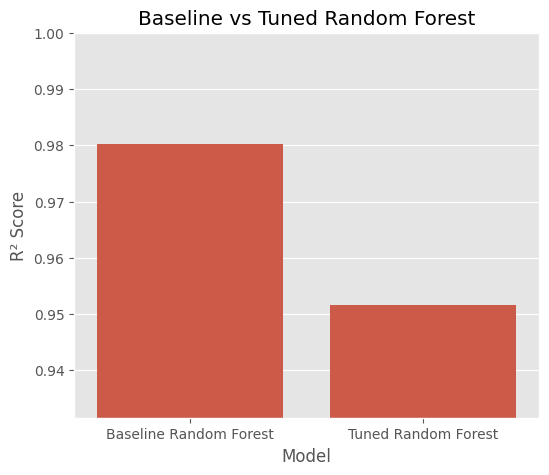

In [74]:
plt.figure(figsize=(6,5))

sns.barplot(

    data=comparison,

    x="Model",

    y="R² Score"

)

plt.title("Baseline vs Tuned Random Forest")

plt.ylim(

    comparison["R² Score"].min() - 0.02,

    1.0

)

plt.show()

In [75]:
best_params = pd.DataFrame(

    list(grid_search.best_params_.items()),

    columns=["Parameter", "Value"]

)

best_params.to_csv(

    "best_random_forest_parameters.csv",

    index=False

)

display(best_params)

,Parameter,Value
0,model__max_depth,None
1,model__max_features,sqrt
2,model__min_samples_leaf,1
3,model__min_samples_split,2
4,model__n_estimators,100


# Section 9 : Model Evaluation & Explainability

In [76]:
y_pred = best_model.predict(X_test)

print("Predictions Generated Successfully.")

Predictions Generated Successfully.


In [77]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

metrics_df = pd.DataFrame({

    "Metric":[
        "MAE",
        "MSE",
        "RMSE",
        "R² Score"
    ],

    "Value":[
        mae,
        mse,
        rmse,
        r2
    ]

})

display(metrics_df)

,Metric,Value
0,MAE,20.189164
1,MSE,38789.941468
2,RMSE,196.951622
3,R² Score,0.951588


In [78]:
prediction_df = pd.DataFrame({

    "Actual Yield": y_test.values,

    "Predicted Yield": y_pred

})

prediction_df["Error"] = (

    prediction_df["Actual Yield"]

    - prediction_df["Predicted Yield"]

)

display(prediction_df.head(20))

,Actual Yield,Predicted Yield,Error
0,3.820000,2.413923,1.406077
1,1.395357,1.576148,-0.180791
2,6.522727,6.694099,-0.171372
3,0.812857,0.948435,-0.135577
4,0.508000,0.619623,-0.111623
5,0.358000,0.626064,-0.268064
6,0.749091,0.975642,-0.226551
7,1.835789,1.969542,-0.133752
8,75.314375,691.919741,-616.605366
9,1.775000,1.671950,0.103050


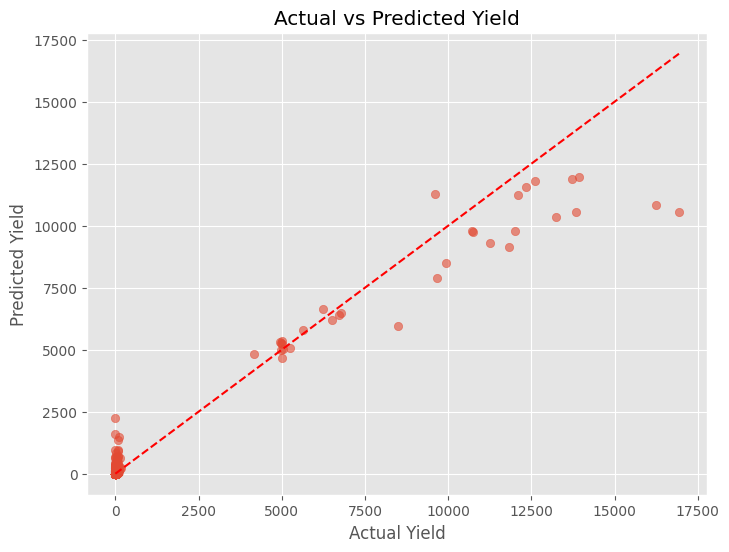

In [79]:
plt.figure(figsize=(8,6))

plt.scatter(

    y_test,

    y_pred,

    alpha=0.6

)

plt.plot(

    [y_test.min(), y_test.max()],

    [y_test.min(), y_test.max()],

    color="red",

    linestyle="--"

)

plt.xlabel("Actual Yield")

plt.ylabel("Predicted Yield")

plt.title("Actual vs Predicted Yield")

plt.show()

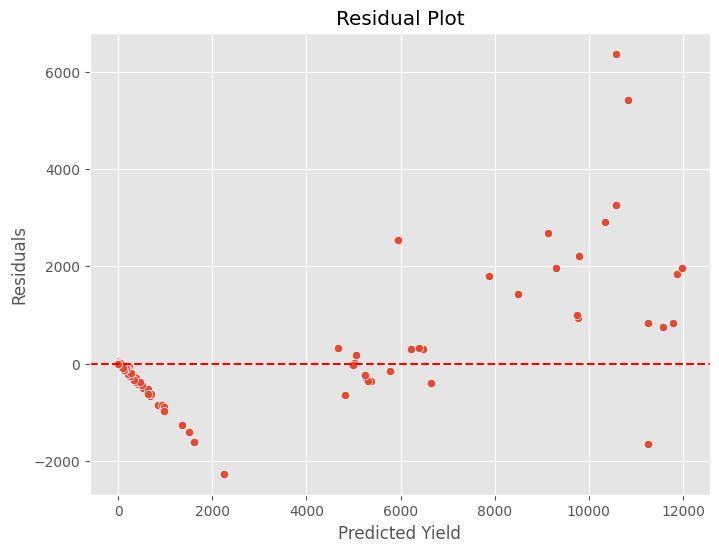

In [80]:
residuals = y_test - y_pred

plt.figure(figsize=(8,6))

sns.scatterplot(

    x=y_pred,

    y=residuals

)

plt.axhline(

    y=0,

    color="red",

    linestyle="--"

)

plt.xlabel("Predicted Yield")

plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

In [81]:
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = best_model.named_steps[
    "model"
].feature_importances_

importance_df = pd.DataFrame({

    "Feature": feature_names,

    "Importance": importance

})

importance_df = importance_df.sort_values(

    by="Importance",

    ascending=False

)

display(importance_df.head(20))

,Feature,Importance
9,categorical__Crop_Coconut,0.596607
92,numerical__Area,0.069149
94,numerical__Fertilizer,0.064927
95,numerical__Pesticide,0.053058
59,categorical__Season_Whole Year,0.033528
93,numerical__Annual_Rainfall,0.031132
91,numerical__Crop_Year,0.020650
90,categorical__State_West Bengal,0.020616
82,categorical__State_Puducherry,0.015198
46,categorical__Crop_Sugarcane,0.013481


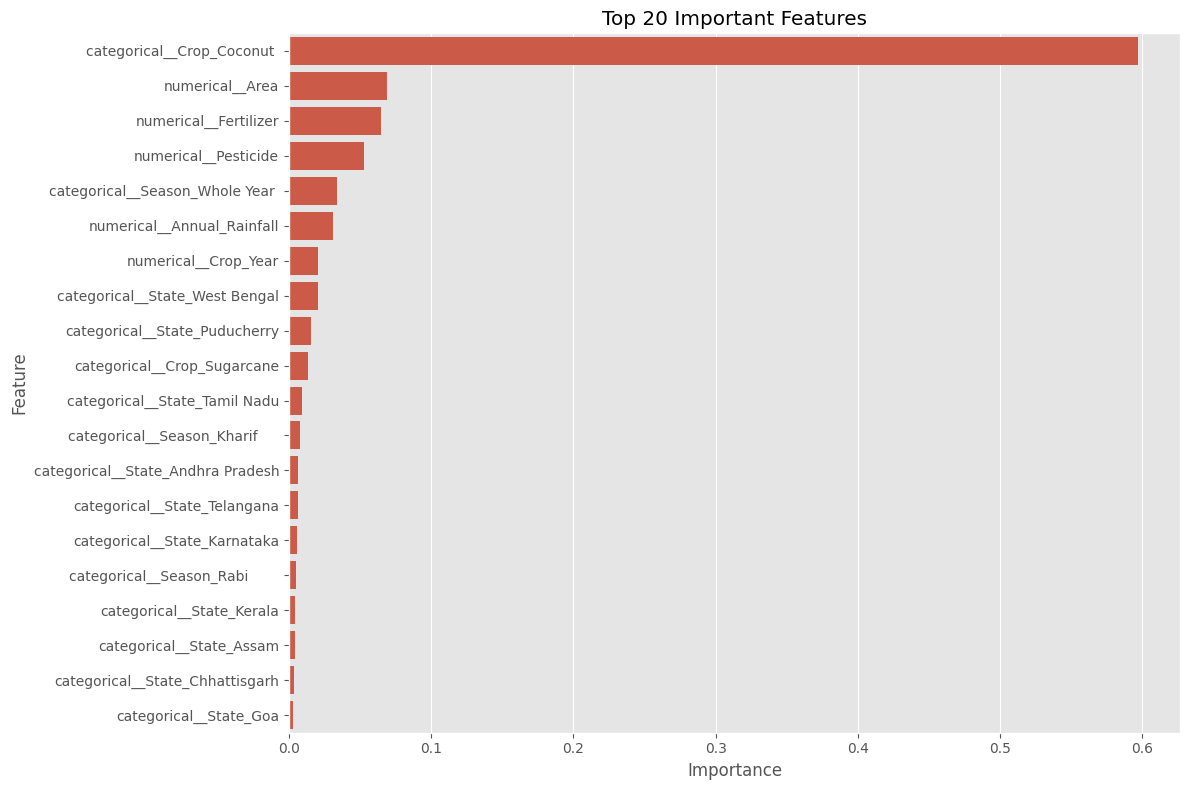

In [82]:
plt.figure(figsize=(12,8))

sns.barplot(

    data=importance_df.head(20),

    y="Feature",

    x="Importance"

)

plt.title("Top 20 Important Features")

plt.tight_layout()

plt.show()

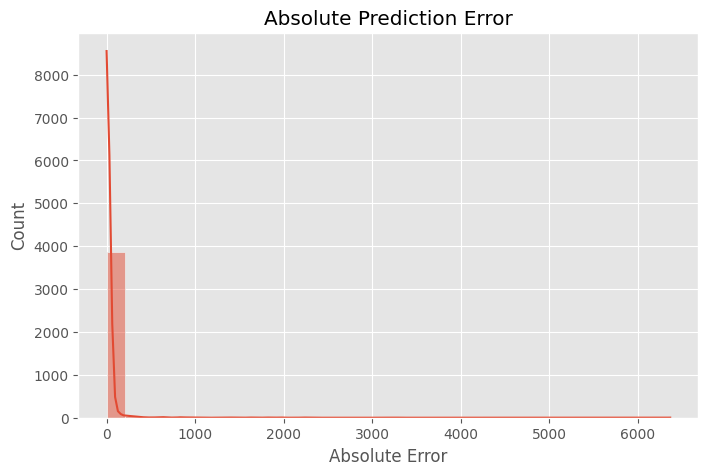

In [83]:
prediction_df["Absolute Error"] = prediction_df[
    "Error"
].abs()

plt.figure(figsize=(8,5))

sns.histplot(

    prediction_df["Absolute Error"],

    bins=30,

    kde=True

)

plt.title("Absolute Prediction Error")

plt.show()

# Save Artifacts

In [84]:
ARTIFACT_DIR = "yield_prediction_artifacts"

MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
REPORTS_DIR = os.path.join(ARTIFACT_DIR, "reports")
PLOTS_DIR = os.path.join(ARTIFACT_DIR, "plots")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

print("Artifact directories created successfully.")

Artifact directories created successfully.


In [85]:
joblib.dump(
    best_model,
    os.path.join(
        MODELS_DIR,
        "yield_prediction_model.pkl"
    )
)

print("Model saved successfully.")

Model saved successfully.


In [86]:
joblib.dump(
    preprocessor,
    os.path.join(
        MODELS_DIR,
        "yield_preprocessor.pkl"
    )
)

print("Preprocessor saved successfully.")

Preprocessor saved successfully.


In [87]:
results_df.to_csv(

    os.path.join(
        REPORTS_DIR,
        "benchmark_results.csv"
    ),

    index=False

)

print("Benchmark report saved.")

Benchmark report saved.


In [88]:
metrics_df.to_csv(

    os.path.join(
        REPORTS_DIR,
        "evaluation_metrics.csv"
    ),

    index=False

)

print("Evaluation metrics saved.")

Evaluation metrics saved.


In [89]:
importance_df.to_csv(

    os.path.join(
        REPORTS_DIR,
        "feature_importance.csv"
    ),

    index=False

)

print("Feature importance saved.")

Feature importance saved.


In [90]:
prediction_df.to_csv(

    os.path.join(
        REPORTS_DIR,
        "test_predictions.csv"
    ),

    index=True

)

print("Predictions saved.")

Predictions saved.


In [91]:
with open(

    os.path.join(
        REPORTS_DIR,
        "model_information.txt"
    ),

    "w"

) as file:

    file.write("Yield Prediction Model\n")
    file.write("="*50 + "\n\n")

    file.write(f"Algorithm : {best_model_name}\n")
    file.write(f"R2 Score  : {r2:.4f}\n")
    file.write(f"MAE       : {mae:.4f}\n")
    file.write(f"MSE       : {mse:.4f}\n")
    file.write(f"RMSE      : {rmse:.4f}\n")

print("Model information saved.")

Model information saved.


In [92]:
plt.savefig(

    os.path.join(
        PLOTS_DIR,
        "actual_vs_predicted.png"
    ),

    dpi=300,

    bbox_inches="tight"

)

<Figure size 640x480 with 0 Axes>

In [93]:
readme = """
Yield Prediction Artifacts

Files Included

models/
    yield_prediction_model.pkl
    yield_preprocessor.pkl
    feature_information.pkl

reports/
    benchmark_results.csv
    evaluation_metrics.csv
    feature_importance.csv
    test_predictions.csv
    model_information.txt

plots/
    Model evaluation figures

Generated By:
YieldCraft AI
"""

with open(

    os.path.join(
        ARTIFACT_DIR,
        "README.txt"
    ),

    "w"

) as f:

    f.write(readme)

print("README created.")

README created.


In [94]:
shutil.make_archive(

    "yield_prediction_artifacts",

    "zip",

    ARTIFACT_DIR

)

print("ZIP archive created successfully.")

ZIP archive created successfully.


# Prediction Pipeline

In [95]:
import joblib
import pandas as pd

MODEL_PATH = "yield_prediction_artifacts/models/yield_prediction_model.pkl"

model = joblib.load(MODEL_PATH)

print("Yield Prediction Model Loaded Successfully.")

Yield Prediction Model Loaded Successfully.


In [96]:
def predict_yield(
    crop,
    crop_year,
    season,
    state,
    area,
    annual_rainfall,
    fertilizer,
    pesticide
):
    """
    Predict crop yield.
    """

    input_df = pd.DataFrame({

        "Crop": [crop],
        "Crop_Year": [crop_year],
        "Season": [season],
        "State": [state],
        "Area": [area],
        "Annual_Rainfall": [annual_rainfall],
        "Fertilizer": [fertilizer],
        "Pesticide": [pesticide]

    })

    prediction = model.predict(input_df)[0]

    return float(prediction)

In [97]:
sample_inputs = pd.DataFrame({

    "Crop":[
        "Rice",
        "Wheat",
        "Maize"
    ],

    "Crop_Year":[
        2018,
        2019,
        2020
    ],

    "Season":[
        "Kharif",
        "Rabi",
        "Kharif"
    ],

    "State":[
        "Karnataka",
        "Punjab",
        "Maharashtra"
    ],

    "Area":[
        1200,
        950,
        800
    ],

    "Annual_Rainfall":[
        950,
        620,
        720
    ],

    "Fertilizer":[
        140,
        170,
        130
    ],

    "Pesticide":[
        20,
        18,
        15
    ]

})

sample_inputs["Predicted_Yield"] = model.predict(sample_inputs)

display(sample_inputs)

,Crop,Crop_Year,Season,State,Area,Annual_Rainfall,Fertilizer,Pesticide,Predicted_Yield
0,Rice,2018,Kharif,Karnataka,1200,950,140,20,32.936441
1,Wheat,2019,Rabi,Punjab,950,620,170,18,43.814034
2,Maize,2020,Kharif,Maharashtra,800,720,130,15,141.874242


In [98]:
summary = sample_inputs[["Predicted_Yield"]].describe()

display(summary)

,Predicted_Yield
count,3.000000
mean,72.874906
std,60.002181
min,32.936441
25%,38.375238
50%,43.814034
75%,92.844138
max,141.874242


In [99]:
def predict_yield_safe(
    crop,
    crop_year,
    season,
    state,
    area,
    annual_rainfall,
    fertilizer,
    pesticide
):

    data = {

        "Crop": crop,
        "Crop_Year": crop_year,
        "Season": season,
        "State": state,
        "Area": area,
        "Annual_Rainfall": annual_rainfall,
        "Fertilizer": fertilizer,
        "Pesticide": pesticide

    }

    validate_input(data)

    return predict_yield(

        crop,
        crop_year,
        season,
        state,
        area,
        annual_rainfall,
        fertilizer,
        pesticide

    )

In [100]:
sample_inputs.to_csv(

    "yield_prediction_artifacts/reports/sample_predictions.csv",

    index=False

)

print("Sample predictions saved.")

Sample predictions saved.
